# GCI World 2026 September — Final Assignment
**Company A (Telecom): Data-driven business proposal**

Rename this file to `[OmnicampusAccountName].ipynb` before submitting.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 120)
RANDOM_STATE = 42

## 2. Load data

In [2]:
client = pd.read_csv('data/Client.csv')
record = pd.read_csv('data/Record.csv')

print('Client:', client.shape)
print('Record:', record.shape)

df = record.merge(client, on='Customer_ID', how='inner')
print('Merged:', df.shape)   # expected: (100000, 100)

Client: (100000, 50)
Record: (100000, 51)
Merged: (100000, 100)


In [3]:
df.head()

,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,Customer_ID,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,-18.9975,0.666667,0.0,0.666667,0.0,6.333333,0.0,52.333333,0.0,42.333333,0.0,45.000000,0.0,0.000000,0.000000,0.000000,18.000000,0.000000,90.643333,0.0,97.176667,0.000000,0.000000,0.000000,0.000000,58.000000,0.0,132.600000,0.0,24.000000,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61,1000001,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,1602,29.66,83.37,32.69,272,116,30,322.0,136.0,38.0,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.98999,2.0,2.0,WCMB,0.0,0.0,O,15.0,S,S,1.0,M,4.0,3.0,C,A,0.0,N,U,U,U,U,U,Y,361.0
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,50.9875,8.333333,0.0,1.000000,0.0,61.333333,0.0,263.333333,0.0,69.000000,0.0,193.333333,0.0,1.666667,6.333333,5.463333,53.000000,0.333333,189.396667,0.0,55.280000,46.333333,24.216667,6.333333,3.696667,83.666667,0.0,75.333333,0.0,157.000000,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56,1000002,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,14624,51.53,479.40,265.89,305,158,40,477.0,275.0,48.0,U,CHICAGO AREA,N,N,NaN,7.0,6.0,WC,1.0,1.0,NaN,1.0,S,S,1.0,M,5.0,1.0,C,A,0.0,Z,U,U,U,U,U,Y,240.0
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,0.0000,0.333333,0.0,0.000000,0.0,2.666667,0.0,9.000000,0.0,0.333333,0.0,6.000000,0.0,0.000000,0.000000,0.000000,0.333333,0.000000,5.426667,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.0,5.193333,0.0,1.000000,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58,1000003,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,7888,34.54,433.98,140.86,12,7,17,11.0,6.0,17.0,S,GREAT LAKES AREA,N,N,29.98999,2.0,1.0,NaN,0.0,0.0,O,7.0,S,M,2.0,M,5.0,2.0,C,A,0.0,N,U,Y,U,U,U,Y,1504.0
3,38.0000,7.50,38.000,0.0000,0.00,0.0,0.0,0.0,0.0,-1.50,0.0000,0.000000,0.0,0.000000,0.0,0.000000,0.0,3.666667,0.0,1.333333,0.0,3.666667,0.0,0.000000,0.000000,0.000000,1.333333,0.000000,8.410000,0.0,0.413333,0.333333,0.256667,0.000000,0.000000,1.333333,0.0,3.380000,0.0,3.666667,0.0,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,0,60,1000004,1,1,Y,B,N,1502,3065.00000,2000.90,1941.81,3035.00,1479,40.45,63.23,30.81,8,3,38,50.0,25.0,40.0,T,CHICAGO AREA,N,N,29.98999,1.0,1.0,NaN,0.0,0.0,NaN,6.0,M,M,4.0,M,6.0,1.0,C,D,0.0,U,Y,U,U,U,U,Y,1812.0
4,55.2300,570.50,71.980,0.0000,0.00,0.0,0.0,0.0,0.0,38.50,0.0000,9.666667,0.0,0.666667,0.0,77.000000,0.0,222.333333,0.0,94.666667,0.0,137.000000,0.0,8.666667,15.000000,11.076667,66.000000,0.000000,285.233333,0.0,106.330000,14.666667,10.816667,0.666667,0.366667,97.333333,0.0,173.476667,0.0,90.333333,0.0,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,0,57,1000005,1,1,Y,A,N,4485,14028.00000,2181.12,2166.48,13965.00,4452,38.69,249.38,79.50,558,191,55,586.0,196.0,80.0,U,NEW ENGLAND AREA,Y,N,149.98999,6.0,4.0,WCMB,0.0,0.0,R,5.0,M,S,1.0,M,6.0,1.0,C,O,0.0,I,U,U,U,U,U,Y,434.0


## 3. Market analysis notes
_Write your market research findings and sources here (cite everything)._

## 4. EDA
### 4.1 Shape, types, missing values

In [4]:
df.info(verbose=False)

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Columns: 100 entries, rev_Mean to eqpdays
dtypes: float64(69), int64(10), str(21)
memory usage: 76.3 MB


In [5]:
missing = df.isna().mean().sort_values(ascending=False)
missing[missing > 0].head(20)

numbcars            0.49366
dwllsize            0.38308
HHstatin            0.37923
ownrent             0.33706
dwlltype            0.31909
lor                 0.30190
income              0.25436
adults              0.23019
infobase            0.22079
hnd_webcap          0.10189
prizm_social_one    0.07388
avg6mou             0.02839
avg6qty             0.02839
avg6rev             0.02839
truck               0.01732
rv                  0.01732
kid11_15            0.01732
kid16_17            0.01732
marital             0.01732
forgntvl            0.01732
dtype: float64

### 4.2 Target distribution

In [6]:
df['churn'].value_counts(normalize=True)

churn
0    0.50438
1    0.49562
Name: proportion, dtype: float64

### 4.3 Hypotheses
_Explore your own hypotheses here (e.g., overage, equipment age, usage change, customer care calls)._

In [7]:
def churn_by_bins(col, q=5):
    tmp = df[[col, 'churn']].dropna().copy()
    tmp['bin'] = pd.qcut(tmp[col], q=q, duplicates='drop')
    result = tmp.groupby('bin', observed=True)['churn'].agg(['mean', 'count'])
    result['mean'].plot(kind='bar', title=f'Churn rate by {col}')
    plt.ylabel('Churn rate'); plt.show()
    return result

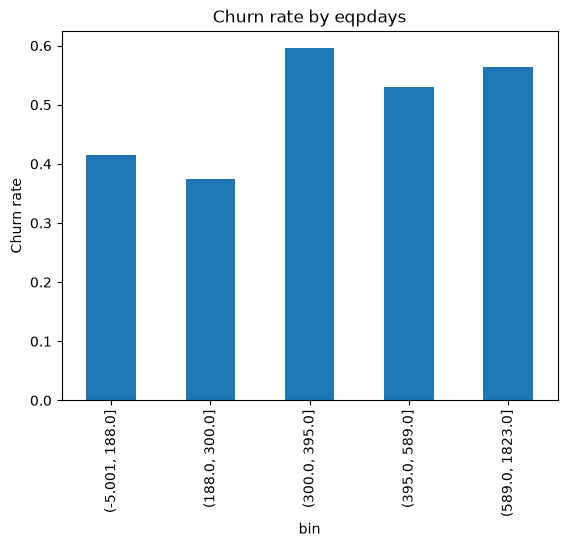

,mean,count
bin,,
"(-5.001, 188.0]",0.415325,20006
"(188.0, 300.0]",0.373817,20082
"(300.0, 395.0]",0.595278,20078
"(395.0, 589.0]",0.530401,19868
"(589.0, 1823.0]",0.563787,19965


In [8]:
churn_by_bins('eqpdays')

In [9]:
bins = [-10, 90, 180, 270, 330, 350, 365, 380, 400, 450, 540, 730, 2000]
df['eqp_bin'] = pd.cut(df['eqpdays'], bins=bins)
df.groupby('eqp_bin', observed=True)['churn'].agg(['mean', 'count'])

,mean,count
eqp_bin,,
"(-10, 90]",0.398654,9655
"(90, 180]",0.438192,8672
"(180, 270]",0.375816,16854
"(270, 330]",0.511841,12330
"(330, 350]",0.620731,4158
"(350, 365]",0.614134,3014
"(365, 380]",0.542477,2931
"(380, 400]",0.562275,3340
"(400, 450]",0.530502,6311


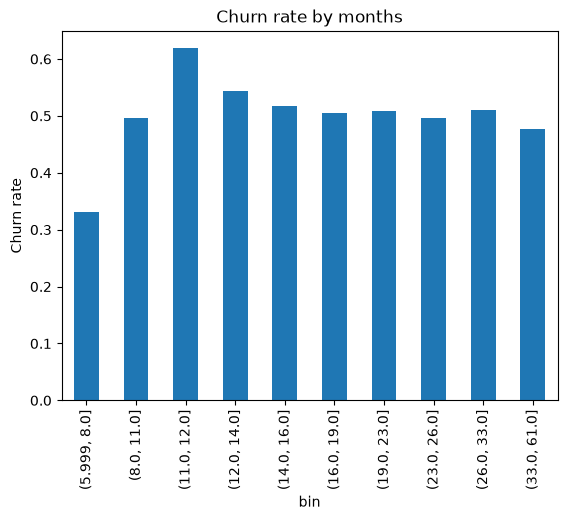

,mean,count
bin,,
"(5.999, 8.0]",0.330634,10002
"(8.0, 11.0]",0.495917,16408
"(11.0, 12.0]",0.618598,6033
"(12.0, 14.0]",0.543664,10203
"(14.0, 16.0]",0.517149,7435
"(16.0, 19.0]",0.505278,10420
"(19.0, 23.0]",0.508052,12481
"(23.0, 26.0]",0.495566,7329
"(26.0, 33.0]",0.510839,10933


In [10]:
churn_by_bins('months', q=10)

In [11]:
(df['eqpdays'] < 0).sum()

np.int64(133)

In [12]:
df['tenure_grp'] = pd.cut(df['months'], [5, 10, 13, 100], labels=['6-10', '11-13', '14+'])
df['eqp_grp'] = pd.cut(df['eqpdays'], [-10, 300, 400, 5000], labels=['<300', '300-400', '400+'])

print(pd.crosstab(df['tenure_grp'], df['eqp_grp'], values=df['churn'], aggfunc='mean').round(3))
print(pd.crosstab(df['tenure_grp'], df['eqp_grp']))

eqp_grp      <300  300-400   400+
tenure_grp                       
6-10        0.321    0.549    NaN
11-13       0.589    0.623  0.566
14+         0.411    0.521  0.547
eqp_grp      <300  300-400   400+
tenure_grp                       
6-10        16972     1409      0
11-13        4905    14374    433
14+         18211     5083  38612


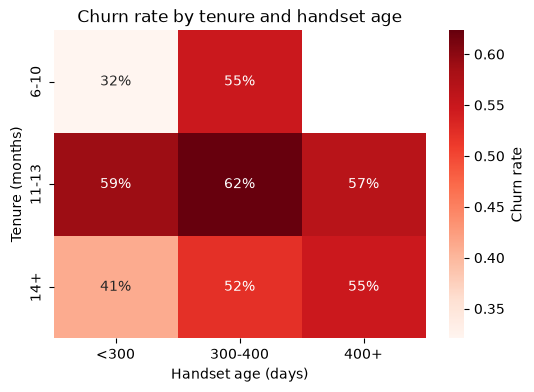

In [13]:
pivot = pd.crosstab(df['tenure_grp'], df['eqp_grp'], values=df['churn'], aggfunc='mean')
plt.figure(figsize=(6, 4))
sns.heatmap(pivot, annot=True, fmt='.0%', cmap='Reds', cbar_kws={'label': 'Churn rate'})
plt.title('Churn rate by tenure and handset age')
plt.xlabel('Handset age (days)'); plt.ylabel('Tenure (months)')
plt.savefig('figures/churn_heatmap.png', dpi=200, bbox_inches='tight')
plt.show()

### Finding: Churn is highest around 12 months

**What I saw:**
- Churn rate is highest when customers are in their 11th–13th month (about 57–62%).
  Even customers with new phones leave at this time.
  This may be because many contracts end after 12 months.
- For customers who stayed more than 14 months, phone age also matters:
  - New phone (less than 300 days): 41% churn
  - Old phone (more than 400 days): 55% churn
- Two big groups:
  - Customers in month 11–13: about 19,700 people
  - Long-term customers with old phones: about 38,600 people

**What this means for the business:**
- Idea A: Give a renewal offer at month 10, before the contract ends.
- Idea B: Give a phone upgrade offer when the phone is about 300 days old.

**Limitation:**
- This only shows a relationship, not a cause.
  Customers with new phones may stay because they signed a new contract.
  The company should test the offer with an A/B test first.

In [14]:
print('Negative eqpdays:', (df['eqpdays'] < 0).sum())

Negative eqpdays: 133


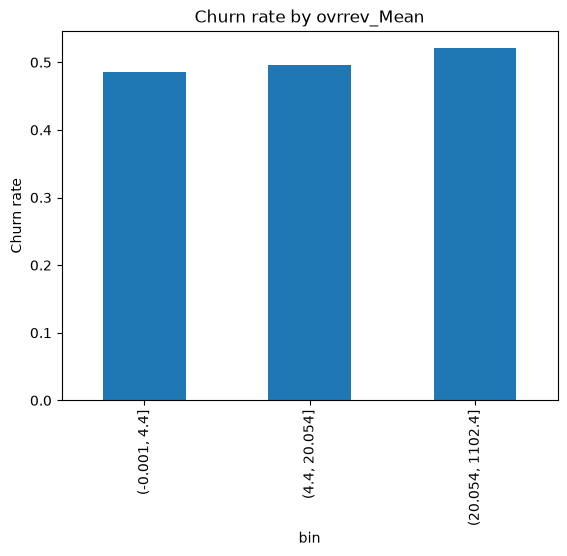

,mean,count
bin,,
"(-0.001, 4.4]",0.485788,59808
"(4.4, 20.054]",0.496735,19906
"(20.054, 1102.4]",0.520598,19929


In [15]:
churn_by_bins('ovrrev_Mean')

In [16]:
df['has_overage'] = (df['ovrrev_Mean'] > 0).astype(int)
df.groupby('has_overage')['churn'].agg(['mean', 'count'])

,mean,count
has_overage,,
0,0.491925,42909
1,0.498397,57091


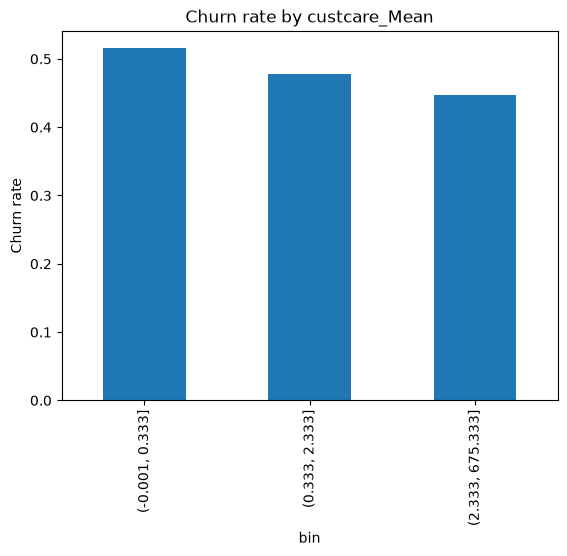

,mean,count
bin,,
"(-0.001, 0.333]",0.515364,62905
"(0.333, 2.333]",0.478218,18065
"(2.333, 675.333]",0.446873,19030


In [17]:
churn_by_bins('custcare_Mean')

In [18]:
df['called_care'] = (df['custcare_Mean'] > 0).astype(int)
df.groupby('called_care')['churn'].agg(['mean', 'count'])

,mean,count
called_care,,
0,0.517615,55692
1,0.467974,44308


In [19]:
df = df[df['eqpdays'] >= 0].copy()
print(df.shape)   

(99866, 105)


### More findings
- **Data cleaning:** 133 customers had negative phone age (`eqpdays` < 0). This is not possible, so I removed them.
- **Overage charges:** No real difference in churn (49.2% vs 49.8%). The "bill shock" idea is not supported.
- **Customer care calls:** Customers who never call customer care churn MORE (51.8%) than customers who call (46.8%).
  These may be "silent churners" — they leave without complaining.
  So the company should contact customers first, not wait for them to call.
  (Limitation: customers who call may also be heavy users. I will check this later.)

### Main levers for the proposal
1. Contract timing (month 11–13)
2. Handset age (for long-term customers)
3. Proactive contact (because silent customers leave)

## 5. Problem definition
_State the business question, target variable, and ML task in a few sentences._

## 6. Preprocessing & feature engineering

## 7. Modeling

## 8. Evaluation
_Model name, metric, score — and comparison with a baseline._

## 9. From model to business proposal
_Quantified impact with stated assumptions._

## 10. References
_List all sources and the AI chat URL(s)._